In [ ]:
import os
import importlib.util

MODEL_DIR = "models"
allModelsPaths = list()

for (root,dirs,files) in os.walk('models/',topdown=True):
  if 'model.py' in files:
    allModelsPaths.append(
      root + '/' + 'model.py'
    )

In [2]:
allModelsPaths

['models/dogsVsCats/model.py',
 'models/mnist/model.py',
 'models/eMnist/model.py',
 'models/fashionMnist/model.py']

In [3]:
def loadModelFromFile(path, funcName):
    spec = importlib.util.spec_from_file_location('loadModel', path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    if hasattr(module, funcName):
        return getattr(module, funcName)()
    raise AttributeError(f"Module {path} does not have a function named {funcName}")

In [4]:
model = loadModelFromFile(
    allModelsPaths[1],
    'loadModel'
)

FileNotFoundError: [Errno 2] No such file or directory: '../models/mnist/best_model.pth'

In [ ]:
model

(mnistModel(
   (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
   (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
   (relu): ReLU()
   (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   (fc1): Linear(in_features=3136, out_features=128, bias=True)
   (fc2): Linear(in_features=128, out_features=10, bias=True)
   (dropout): Dropout(p=0.5, inplace=False)
 ),
 Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)))

In [ ]:
from segmentation.riseMask import riseMask
import numpy as np
import cv2
import matplotlib.pyplot as plt
masks = riseMask(
    224, 224
)

(25, 224, 224)


In [ ]:
masks.shape

(25, 224, 224)

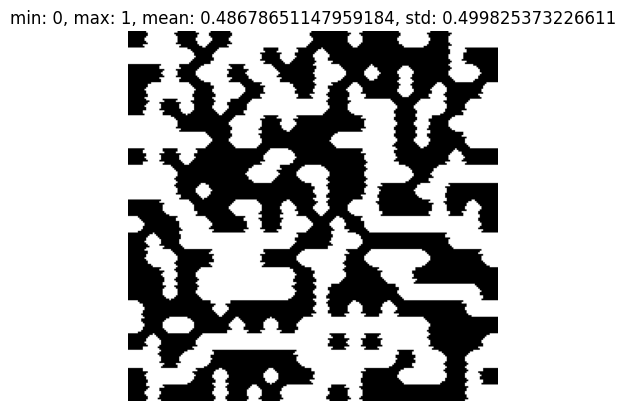

In [ ]:
plt.imshow(
    masks[0], cmap='gray'
)
plt.axis('off')
plt.title(f'min: {np.min(masks[0])}, max: {np.max(masks[0])}, mean: {np.mean(masks[0])}, std: {np.std(masks[0])}')
plt.show()

In [ ]:
from segmentation.seed import seed
from segmentation.slic import slic
import matplotlib.pyplot as plt
import cv2
import numpy as np

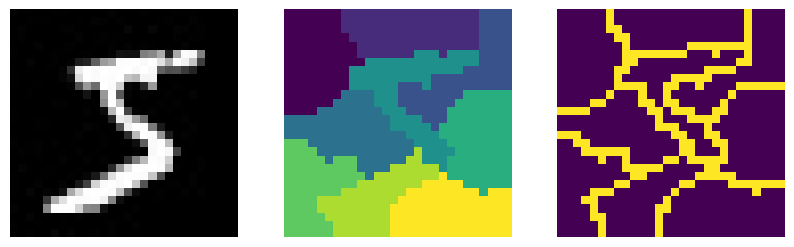

In [ ]:
image = cv2.imread('random.jpg')
fig, axs = plt.subplots(1, 3, figsize=(10, 5))
labels, masks = seed(image, 20)
axs[0].imshow(image)
axs[0].axis('off')
axs[1].imshow(labels)
axs[1].axis('off')
axs[2].imshow(masks)
axs[2].axis('off')
plt.show()

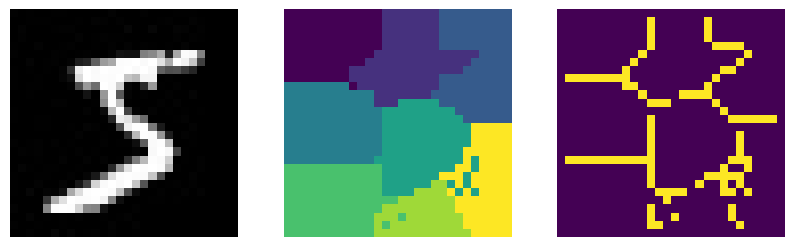

In [ ]:
image = cv2.imread('random.jpg')
fig, axs = plt.subplots(1, 3, figsize=(10, 5))
labels, masks = slic(image, 10)
axs[0].imshow(image)
axs[0].axis('off')
axs[1].imshow(labels)
axs[1].axis('off')
axs[2].imshow(masks)
axs[2].axis('off')
plt.show()

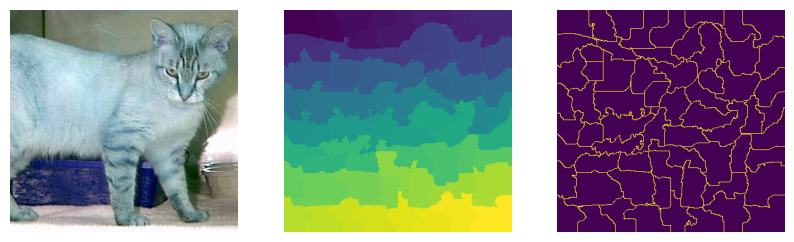

In [ ]:
image = cv2.imread('10000.jpg')
fig, axs = plt.subplots(1, 3, figsize=(10, 5))
labels, masks = seed(image, 100)
axs[0].imshow(image)
axs[0].axis('off')
axs[1].imshow(labels)
axs[1].axis('off')
axs[2].imshow(masks)
axs[2].axis('off')
plt.show()

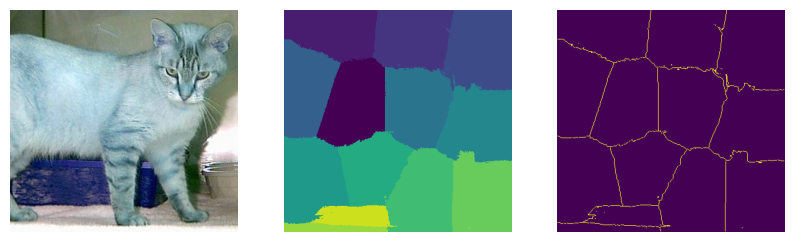

In [ ]:
image = cv2.imread('10000.jpg')
fig, axs = plt.subplots(1, 3, figsize=(10, 5))
labels, masks = slic(image, 100)
axs[0].imshow(image)
axs[0].axis('off')
axs[1].imshow(labels)
axs[1].axis('off')
axs[2].imshow(masks)
axs[2].axis('off')
plt.show()